In [5]:
!pip install roboflow ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 48.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
!pip install roboflow
from roboflow import Roboflow
rf = Roboflow(api_key=api)
project = rf.workspace("alfadhul-almubarak").project("bahrain_currency_object_detector")
version = project.version(2)
dataset = version.download("yolo26")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 126.6 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Bahrain_Currency_Object_Detector-2 in yolo26:: 100%|██████████| 6989/6989 [00:04<00:00, 1423.80it/s]


In [6]:
from ultralytics import YOLO
#model = YOLO("yolo26s.yaml") # CNN arch, start random weights
model = YOLO("yolo26l.pt") # pretrained model -> person -> I wanna finetune it -> Mask/NO mask

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [7]:
results = model("/content/Bahrain_Currency_Object_Detector-2/train/images/-_-0-_jpg.rf.11f4f7a8ba8cb74d60f8954db9a0b3ad.jpg")


image 1/1 /content/Bahrain_Currency_Object_Detector-2/train/images/-_-0-_jpg.rf.11f4f7a8ba8cb74d60f8954db9a0b3ad.jpg: 640x640 (no detections), 75.0ms
Speed: 55.8ms preprocess, 75.0ms inference, 3.3ms postprocess per image at shape (1, 3, 640, 640)


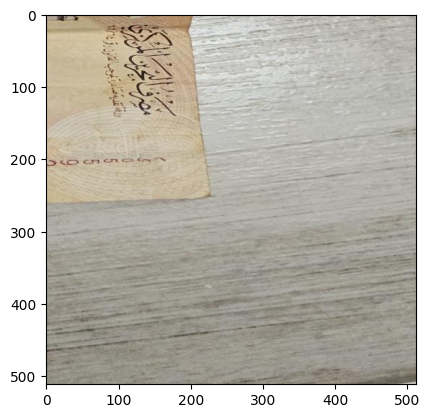

In [8]:
import matplotlib.pyplot as plt
plt.imshow(results[0].plot()[..., ::-1]);

In [9]:
model.train(data='/content/Bahrain_Currency_Object_Detector-2/data.yaml', epochs=5)

Ultralytics 8.4.197 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Bahrain_Currency_Object_Detector-2/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a27704c5130>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
  

In [10]:
finetuned_model = YOLO('/content/runs/detect/train/weights/best.pt')

In [11]:
results = finetuned_model("/content/Bahrain_Currency_Object_Detector-2/train/images/-_-0-_jpg.rf.11f4f7a8ba8cb74d60f8954db9a0b3ad.jpg")


image 1/1 /content/Bahrain_Currency_Object_Detector-2/train/images/-_-0-_jpg.rf.11f4f7a8ba8cb74d60f8954db9a0b3ad.jpg: 640x640 1 0_5, 73.1ms
Speed: 4.6ms preprocess, 73.1ms inference, 3.3ms postprocess per image at shape (1, 3, 640, 640)


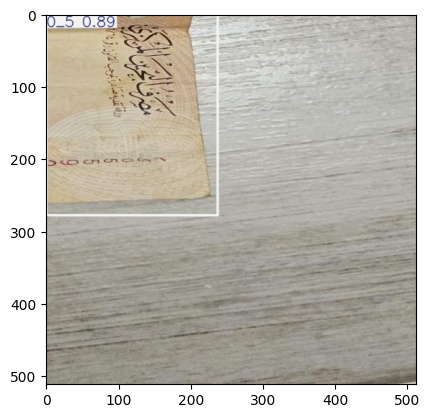

In [12]:
plt.imshow(results[0].plot()[..., ::-1]);